# Train the compact CNN

This notebook trains the compact custom CNN (CCCNN) on the processed 64x64 patches. Run the preprocessing notebook first so that data_processed contains the class folders. The notebook creates a grouped train, validation, and test split, trains the model, saves the best validation checkpoint, and includes prediction cells for held-out dataset patches and a user image.

Patches with the same source fabric ID stay in one split. This gives a more realistic test of generalization to unseen fabric images.


In [3]:
from pathlib import Path
from collections import Counter
import random
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import cv2
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def find_project_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "data_processed").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("Could not find the project root with data_processed/ and notebooks/.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / "data_processed"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = ARTIFACT_DIR / "ccc_nn_best.pt"
SPLIT_PATH = ARTIFACT_DIR / "split_manifest.csv"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SIZE = (64, 64)
BATCH_SIZE = 64
MAX_EPOCHS = 25
PATIENCE = 5
LEARNING_RATE = 1e-3

print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)
print("Processed images:", DATA_DIR)


FileNotFoundError: Could not find the project root with data_processed/ and notebooks/.

## Load paths and make a grouped split

Filenames in this dataset use the source-image ID before _patch. We use that ID as the group when splitting. The validation and test proportions are approximate because the split keeps each source image intact.


In [ ]:
class_names = sorted(path.name for path in DATA_DIR.iterdir() if path.is_dir())
if not class_names:
    raise FileNotFoundError(f"No class folders found in {DATA_DIR}")

records = []
for label_id, class_name in enumerate(class_names):
    for path in sorted((DATA_DIR / class_name).glob("*.png")):
        source_id = path.stem.split("_patch", 1)[0]
        if source_id == path.stem:
            raise ValueError(f"Expected a source ID followed by _patch in filename: {path.name}")
        records.append({
            "path": path,
            "relative_path": path.relative_to(PROJECT_ROOT).as_posix(),
            "class_name": class_name,
            "label": label_id,
            "source_id": source_id,
        })

if not records:
    raise FileNotFoundError(f"No PNG patches found in {DATA_DIR}")

groups = np.array([r["source_id"] for r in records])
indices = np.arange(len(records))
trainval_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED).split(indices, groups=groups))
train_idx_local, val_idx_local = next(
    GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SEED + 1)
    .split(trainval_idx, groups=groups[trainval_idx])
)
train_idx = trainval_idx[train_idx_local]
val_idx = trainval_idx[val_idx_local]

for split_name, split_idx in [("train", train_idx), ("validation", val_idx), ("test", test_idx)]:
    present = {records[i]["class_name"] for i in split_idx}
    missing = set(class_names) - present
    if missing:
        raise ValueError(f"{split_name} split is missing classes: {sorted(missing)}. Rerun with another SEED.")

split_rows = []
for split_name, split_idx in [("train", train_idx), ("validation", val_idx), ("test", test_idx)]:
    for i in split_idx:
        split_rows.append({**records[i], "path": str(records[i]["path"]), "split": split_name})
manifest = pd.DataFrame(split_rows)
manifest.drop(columns=["path"]).to_csv(SPLIT_PATH, index=False)

summary = pd.crosstab(manifest["split"], manifest["class_name"])
summary["total"] = summary.sum(axis=1)
display(summary)
print("Grouped split manifest saved to:", SPLIT_PATH)


class_name,good,hole,objects,oil spot,thread error,total
split,,,,,,
test,3481,52,141,102,64,3840
train,16196,233,562,427,438,17856
validation,3493,52,134,107,118,3904


Grouped split manifest saved to: C:\Users\pradh\OneDrive\Desktop\FabricDefectDetectionDIP\artifacts\split_manifest.csv


## Dataset and augmentation

Training batches use weighted sampling to show defect classes more often. Training images receive random flips and small rotations; defect images also receive mild brightness and contrast variation. Validation and test images are not augmented.


In [ ]:
class FabricPatchDataset(Dataset):
    def __init__(self, rows, training=False):
        self.rows = rows
        self.training = training
        self.to_tensor = transforms.ToTensor()
        self.color_jitter = transforms.ColorJitter(brightness=0.12, contrast=0.12)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(row["path"]) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
        if self.training:
            if random.random() < 0.5:
                image = ImageOps.mirror(image)
            if random.random() < 0.5:
                image = ImageOps.flip(image)
            angle = random.uniform(-10, 10)
            image = image.rotate(angle, resample=Image.Resampling.BILINEAR)
            if row["class_name"] != "good" and random.random() < 0.5:
                image = self.color_jitter(image)
        return self.to_tensor(image), int(row["label"])

train_rows = [records[i] for i in train_idx]
val_rows = [records[i] for i in val_idx]
test_rows = [records[i] for i in test_idx]

train_counts = Counter(row["label"] for row in train_rows)
sample_weights = [1.0 / np.sqrt(train_counts[row["label"]]) for row in train_rows]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(FabricPatchDataset(train_rows, training=True), batch_size=BATCH_SIZE, sampler=sampler, num_workers=0)
val_loader = DataLoader(FabricPatchDataset(val_rows), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(FabricPatchDataset(test_rows), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print("Training samples:", len(train_rows), "| validation:", len(val_rows), "| test:", len(test_rows))


Training samples: 17856 | validation: 3904 | test: 3840


## Define the CCCNN

Each block has two 3x3 convolution, batch-normalization, and ReLU layers, followed by 2x2 max pooling. Global average pooling keeps the classifier head small.


In [ ]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

    def forward(self, x):
        return self.layers(x)

class CCCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),
            ConvBlock(32, 64),
            ConvBlock(64, 128),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)

model = CCCNN(num_classes=len(class_names)).to(DEVICE)
print(model)


CCCNN(
  (features): Sequential(
    (0): ConvBlock(
      (layers): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (layers): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(64, ep

## Train with class-weighted focal loss

The loss gives more weight to rare classes and focuses on examples the model currently finds difficult. Training stops when validation macro-F1 no longer improves.


In [ ]:
class_weights = torch.tensor(
    [len(train_rows) / (len(class_names) * train_counts[i]) for i in range(len(class_names))],
    dtype=torch.float32,
    device=DEVICE,
)
class_weights = class_weights / class_weights.mean()

class FocalLoss(nn.Module):
    def __init__(self, alpha, gamma=2.0):
        super().__init__()
        self.register_buffer("alpha", alpha)
        self.gamma = gamma

    def forward(self, logits, targets):
        log_prob = torch.log_softmax(logits, dim=1)
        log_pt = log_prob.gather(1, targets.unsqueeze(1)).squeeze(1)
        pt = log_pt.exp()
        alpha_t = self.alpha[targets]
        return (-alpha_t * (1 - pt).pow(self.gamma) * log_pt).mean()

criterion = FocalLoss(class_weights, gamma=2.0)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    y_true, y_pred = [], []
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(logits.argmax(1).cpu().numpy())
    return total_loss / len(loader.dataset), f1_score(y_true, y_pred, average="macro", zero_division=0)

history = []
best_val_f1 = -1.0
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_f1 = run_epoch(train_loader, training=True)
    val_loss, val_f1 = run_epoch(val_loader, training=False)
    history.append({"epoch": epoch, "train_loss": train_loss, "train_macro_f1": train_f1, "val_loss": val_loss, "val_macro_f1": val_f1})
    print(f"Epoch {epoch:02d}/{MAX_EPOCHS} | train loss {train_loss:.4f} | train macro-F1 {train_f1:.4f} | val loss {val_loss:.4f} | val macro-F1 {val_f1:.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        epochs_without_improvement = 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "image_size": IMAGE_SIZE,
        }, MODEL_PATH)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping after {epoch} epochs.")
            break

history_df = pd.DataFrame(history)
history_df.to_csv(ARTIFACT_DIR / "training_history.csv", index=False)
best_checkpoint = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True)
model.load_state_dict(best_checkpoint["model_state_dict"])
print("Best validation macro-F1:", round(best_val_f1, 4))
print("Saved model:", MODEL_PATH)


Epoch 01/25 | train loss 0.2777 | train macro-F1 0.2827 | val loss 0.1275 | val macro-F1 0.2882
Epoch 02/25 | train loss 0.2447 | train macro-F1 0.3392 | val loss 0.3878 | val macro-F1 0.0309
Epoch 03/25 | train loss 0.2269 | train macro-F1 0.3894 | val loss 0.1633 | val macro-F1 0.2321
Epoch 04/25 | train loss 0.2134 | train macro-F1 0.4236 | val loss 0.1980 | val macro-F1 0.1892
Epoch 05/25 | train loss 0.2046 | train macro-F1 0.4170 | val loss 0.1022 | val macro-F1 0.1561


## Training history

The saved checkpoint is the epoch with the highest validation macro-F1.


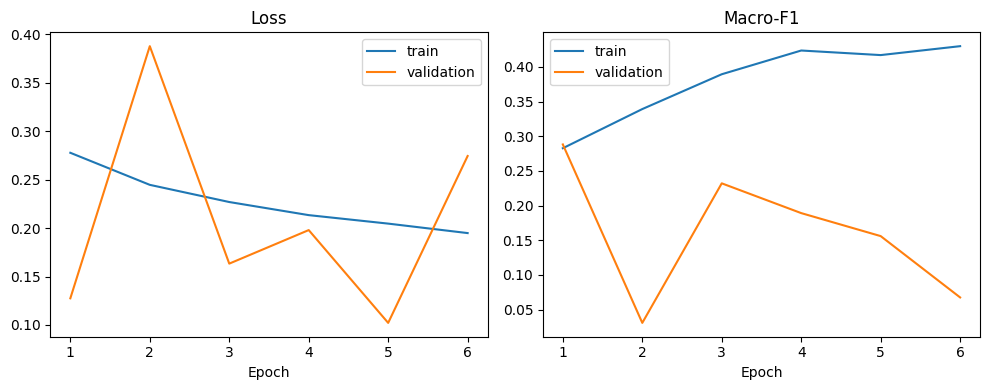

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history_df["epoch"], history_df["train_macro_f1"], label="train")
axes[1].plot(history_df["epoch"], history_df["val_macro_f1"], label="validation")
axes[1].set_title("Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()


## Try held-out dataset patches

This cell displays one test patch from each class and the model prediction. Full test-set metrics are produced by the evaluation notebook.


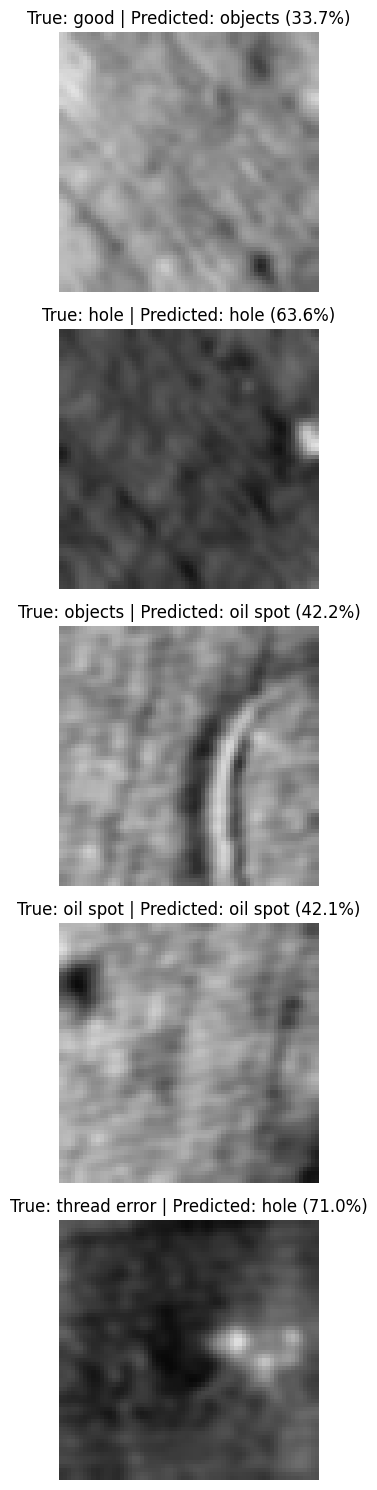

In [ ]:
model.eval()

def predict_pil(image):
    image = ImageOps.exif_transpose(image).convert("RGB").resize(IMAGE_SIZE, Image.Resampling.BICUBIC)
    tensor = transforms.ToTensor()(image).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        probabilities = torch.softmax(model(tensor), dim=1)[0].cpu().numpy()
    pred_id = int(probabilities.argmax())
    return class_names[pred_id], float(probabilities[pred_id]), probabilities

fig, axes = plt.subplots(len(class_names), 1, figsize=(5, 3 * len(class_names)))
axes = np.atleast_1d(axes)
for ax, class_name in zip(axes, class_names):
    row = next(item for item in test_rows if item["class_name"] == class_name)
    with Image.open(row["path"]) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        predicted, confidence, _ = predict_pil(image)
        ax.imshow(image)
    ax.set_title(f"True: {class_name} | Predicted: {predicted} ({confidence:.1%})")
    ax.axis("off")
plt.tight_layout()
plt.show()


## Try a user image

Set USER_IMAGE_PATH to a local image path and run the cell. The image is resized to 64x64 for inference. If the image is raw, the same gamma, contrast, and Gaussian steps used by the preprocessing notebook are applied first. Leave the value as None to skip.


In [ ]:
USER_IMAGE_PATH = None  # Example: r"C:\path\to\fabric_patch.png"

def preprocess_user_image(image):
    image = ImageOps.exif_transpose(image).convert("RGB").resize(IMAGE_SIZE, Image.Resampling.BICUBIC)
    array = np.asarray(image, dtype=np.uint8)
    inverse_gamma = 1.0 / 0.8
    lut = np.array([((value / 255.0) ** inverse_gamma) * 255 for value in range(256)], dtype=np.uint8)
    array = cv2.LUT(array, lut)
    array = cv2.normalize(array, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
    return cv2.GaussianBlur(array, (5, 5), sigmaX=0)

if USER_IMAGE_PATH is None:
    print("Set USER_IMAGE_PATH to an image file to test it.")
else:
    user_path = Path(USER_IMAGE_PATH).expanduser()
    if not user_path.is_file():
        raise FileNotFoundError(f"Image not found: {user_path}")
    with Image.open(user_path) as image:
        processed = preprocess_user_image(image)
    predicted, confidence, probabilities = predict_pil(Image.fromarray(processed))
    plt.figure(figsize=(4, 4))
    plt.imshow(processed)
    plt.title(f"Prediction: {predicted} ({confidence:.1%})")
    plt.axis("off")
    plt.show()
    display(pd.DataFrame({"class": class_names, "probability": probabilities}).sort_values("probability", ascending=False))


Set USER_IMAGE_PATH to an image file to test it.
